In [19]:
import os
import yaml
from ml_collections.config_dict import ConfigDict

import numpy as np
import timm

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset, Subset
from model.utils.train_utils import load_model, load_dataset, load_checkpoint, evaluate

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt

In [2]:
checkpoint_path = "../outputs/basic_contrastive/checkpoint-100.pth"

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = "cpu"

In [4]:
config_file = yaml.load(open("../configs/step1_basic_contrastive.yaml", "r"), yaml.FullLoader)
config = ConfigDict(config_file)

In [26]:
dataset1 = load_dataset(config.dataset1)
dataset2 = load_dataset(config.dataset2)

concat_dataset = ConcatDataset([dataset1, dataset2])
dataset = Subset(concat_dataset, indices=range(1000))

In [25]:
len(concat_dataset)

49097

In [27]:
len(dataset)

1000

In [6]:
# Load pretrained UNI model (UNI checkpoints "pytorch_model.bin" should be downloaded in assets)
pretrained_ckpt_dir = config.model.pretrained_image_encoder_ckpt_path
os.makedirs(pretrained_ckpt_dir, exist_ok=True)
pretrained_image_encoder = timm.create_model(
    "vit_large_patch16_224",
    img_size=224,
    patch_size=16,
    init_values=1e-5,
    num_classes=0,
    dynamic_img_size=True,
)
pretrained_image_encoder.load_state_dict(
    torch.load(
        os.path.join(pretrained_ckpt_dir, "pytorch_model.bin"), map_location="cpu"
    ),
    strict=True,
)
pretrained_image_encoder.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): 

In [7]:
model, optimizer, lr_scheduler = load_model(config, pretrained_image_encoder)

In [8]:
load_checkpoint(model, optimizer, lr_scheduler, checkpoint_path)

model.to(device)
model.eval()

Loaded checkpoint from ../outputs/basic_contrastive/checkpoint-100.pth at step 100


base_contrastive(
  (image_encoder): VisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
    (patch_drop): Identity()
    (norm_pre): Identity()
    (blocks): Sequential(
      (0): Block(
        (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1024, out_features=3072, bias=True)
          (q_norm): Identity()
          (k_norm): Identity()
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=1024, out_features=1024, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (drop_path1): Identity()
        (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (act): GEL

In [29]:
dataloader = DataLoader(dataset, batch_size=64, shuffle=False)

In [30]:
loss, image_embedding, spatial_embedding = evaluate(model, dataloader, device)

KeyboardInterrupt: 

In [ ]:
image_embedding

# Plot

In [31]:
intermediate = torch.load("../outputs/embedding_step_499.pt")

spatial_embedding, image_embedding = intermediate['spatial_embedding'], intermediate['image_embedding']

In [32]:
spatial_embedding.shape

torch.Size([16, 128])

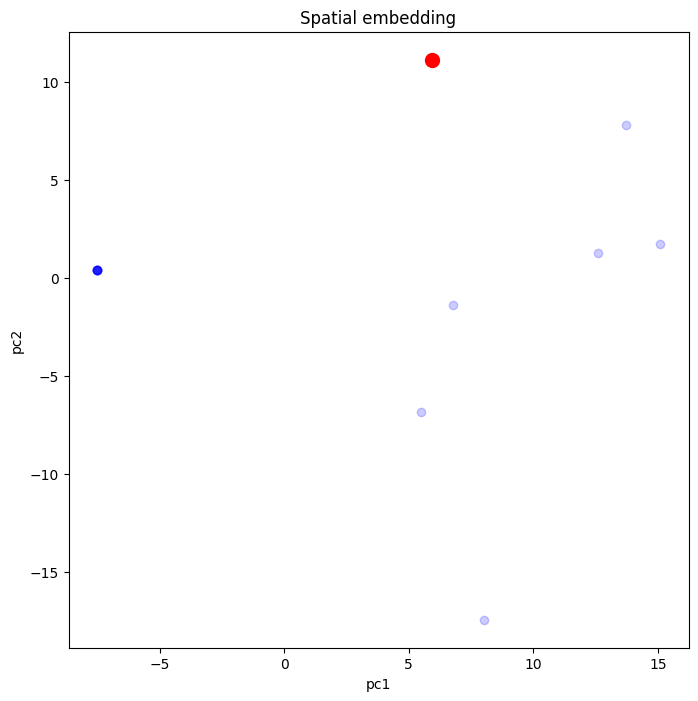

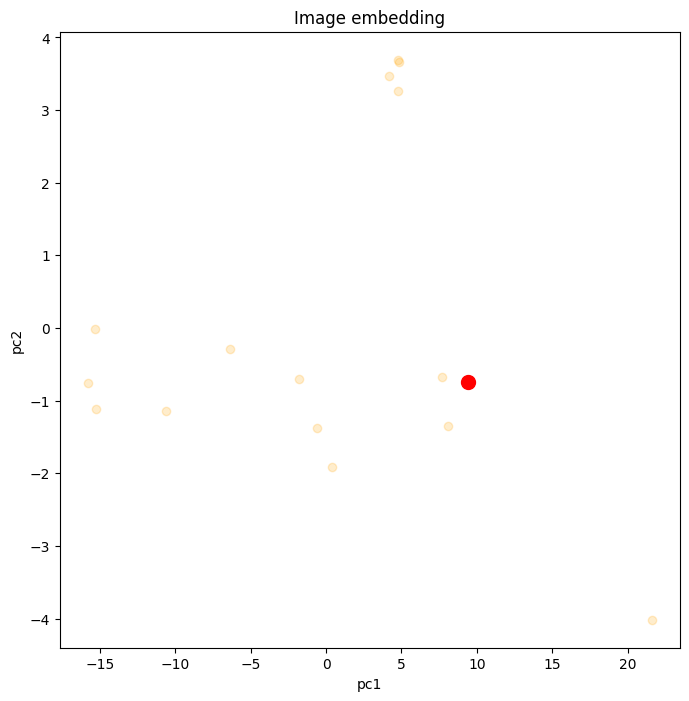

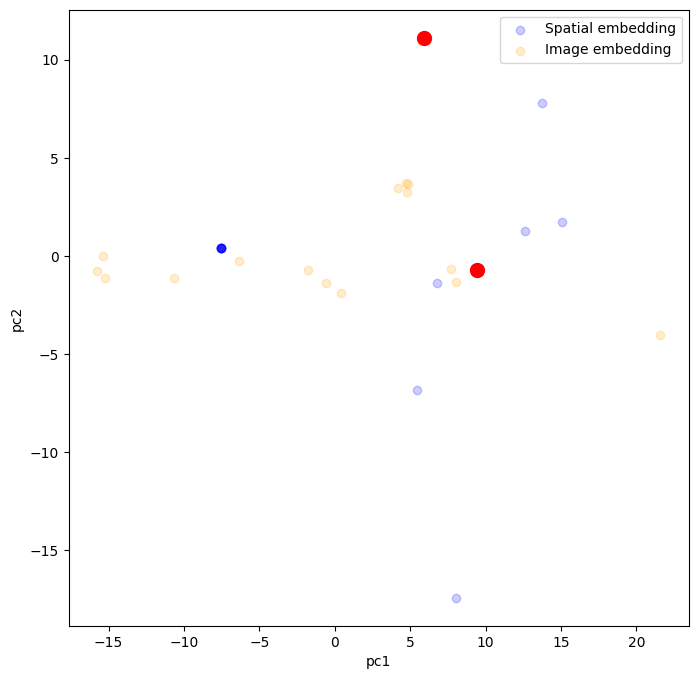

In [24]:
A, B = spatial_embedding.detach().numpy(), image_embedding.detach().numpy()

scaler = StandardScaler()
A = scaler.fit_transform(A)
B = scaler.fit_transform(B)

# Step 1: 먼저 A, B 각각을 낮은 차원 (예: 5)으로 줄임
pca_A = PCA(n_components=5).fit_transform(A)
pca_B = PCA(n_components=5).fit_transform(B)

# Step 2: A, B를 세로로 붙여서 같이 PCA (같은 feature 수니까 가능)
AB = np.concatenate([pca_A, pca_B], axis=0)  # shape = (200, 50)

# Step 3: 같은 공간에 다시 PCA
joint = np.concatenate([pca_A, pca_B], axis=0)
joint_pca = PCA(n_components=2).fit_transform(joint)

pca_A_2d = joint_pca[:len(pca_A)]
pca_B_2d = joint_pca[len(pca_A):]

# 시각화
plt.figure(figsize=(8, 8))
plt.scatter(pca_A[:, 0], pca_A[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.scatter(pca_A[10, 0], pca_A[10, 1], c='red', marker='o', s=100)
plt.title("Spatial embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))
plt.scatter(pca_B[:, 0], pca_B[:, 1], label='Image embedding', c='orange', alpha=0.2)
plt.scatter(pca_B[10, 0], pca_B[10, 1], c='red', marker='o', s=100)
plt.title("Image embedding")
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()

plt.figure(figsize=(8, 8))

plt.scatter(pca_A_2d[:, 0], pca_A_2d[:, 1], label='Spatial embedding', c='blue', alpha=0.2)
plt.scatter(pca_B_2d[:, 0], pca_B_2d[:, 1], label='Image embedding', c='orange', alpha=0.2)

plt.scatter(pca_A_2d[10, 0], pca_A_2d[10, 1], c='red', marker='o', s=100)
plt.scatter(pca_B_2d[10, 0], pca_B_2d[10, 1], c='red', marker='o', s=100)

plt.legend()
plt.xlabel("pc1")
plt.ylabel("pc2")
plt.show()